# 06 — Backlog Analysis

## Sales Order, Backlog & Inventory Analytics

### Objective

This notebook analyzes sales order backlog to understand the scale, value, severity, and distribution of unfulfilled customer demand.

The analysis focuses on:

- Overall backlog KPIs
- Backlog order volume and value
- Backlog percentage and severity
- Backlog trends over time
- Backlog by order priority
- Backlog by sales channel
- Backlog by customer segment and region
- Backlog by product and category
- High-value backlog exposure
- Backlog concentration and key business risks

Inventory availability, shipment performance, and supplier performance are analyzed separately in their respective notebooks.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt1
from pathlib import Path

print("Pandas version :", pd.__version__)
print("NumPy version  :", np.__version__)

print("\nBacklog Analysis environment initialized successfully.")

Pandas version : 3.0.6
NumPy version  : 2.5.3

Backlog Analysis environment initialized successfully.


## Step 2 — Define Feature-Engineered Data Path

Define the project directory and the location of the feature-engineered datasets.

Backlog Analysis will use the analysis-ready datasets produced by `04_Feature_Engineering.ipynb`.

In [2]:
# Define project paths

project_path = Path.cwd().parent

featured_data_path = (
    project_path / "data" / "featured"
)

print("Project Path       :", project_path)
print("Featured Data Path :", featured_data_path)

print(
    "\nFeatured Data Folder Exists :",
    featured_data_path.exists()
)

Project Path       : c:\Users\Admin\OneDrive\Documents\Sales_Order_Backlog_Inventory_Analytics
Featured Data Path : c:\Users\Admin\OneDrive\Documents\Sales_Order_Backlog_Inventory_Analytics\data\featured

Featured Data Folder Exists : True


## Step 3 — Load Backlog Analysis Datasets

Load the feature-engineered datasets required for Backlog Analysis.

The analysis uses:

- Sales Orders
- Sales Order Items
- Customers
- Products
- Warehouses

These datasets provide the order-level and line-level backlog information required for detailed backlog analysis.

In [3]:
# Load datasets required for Backlog Analysis

sales_orders = pd.read_csv(
    featured_data_path / "sales_orders_featured.csv",
    parse_dates=[
        "order_date",
        "requested_delivery_date"
    ]
)

sales_order_items = pd.read_csv(
    featured_data_path / "sales_order_items_featured.csv",
    parse_dates=["order_date"]
)

customers = pd.read_csv(
    featured_data_path / "customers_featured.csv",
    parse_dates=["customer_since"]
)

products = pd.read_csv(
    featured_data_path / "products_featured.csv"
)

warehouses = pd.read_csv(
    featured_data_path / "warehouses_featured.csv"
)


backlog_datasets = {
    "Sales Orders": sales_orders,
    "Sales Order Items": sales_order_items,
    "Customers": customers,
    "Products": products,
    "Warehouses": warehouses
}


print("Backlog Analysis datasets loaded successfully.\n")

for name, df in backlog_datasets.items():
    print(
        f"{name:<20} "
        f"{df.shape[0]:>7,} rows × "
        f"{df.shape[1]:>2} columns"
    )

Backlog Analysis datasets loaded successfully.

Sales Orders          25,000 rows × 26 columns
Sales Order Items     61,397 rows × 20 columns
Customers              2,500 rows ×  6 columns
Products                 500 rows × 10 columns
Warehouses                 6 rows ×  5 columns


## Step 4 — Overall Backlog KPIs

Calculate the core backlog KPIs to understand the overall scale of unfulfilled customer demand.

Key metrics include:

- Total Orders
- Orders with Backlog
- Backlog Order Rate
- Total Ordered Quantity
- Total Fulfilled Quantity
- Total Backlog Quantity
- Quantity Backlog Rate
- Total Order Value
- Total Backlog Value
- Value Backlog Rate
- Average Backlog Value per Backlogged Order

In [4]:
# Overall Backlog KPIs

total_orders = sales_orders["order_id"].nunique()

backlog_orders = (
    sales_orders.loc[
        sales_orders["backlog_qty"] > 0,
        "order_id"
    ].nunique()
)

backlog_order_rate = (
    backlog_orders / total_orders * 100
)


total_ordered_qty = (
    sales_orders["ordered_qty"].sum()
)

total_fulfilled_qty = (
    sales_orders["fulfilled_qty"].sum()
)

total_backlog_qty = (
    sales_orders["backlog_qty"].sum()
)

quantity_backlog_rate = (
    total_backlog_qty
    / total_ordered_qty
    * 100
)


total_order_value = (
    sales_orders["order_value"].sum()
)

total_backlog_value = (
    sales_orders["backlog_value"].sum()
)

value_backlog_rate = (
    total_backlog_value
    / total_order_value
    * 100
)


avg_backlog_value = (
    total_backlog_value
    / backlog_orders
)


print("OVERALL BACKLOG KPIs\n")

print(
    f"Total Orders                       : "
    f"{total_orders:,}"
)

print(
    f"Orders with Backlog                : "
    f"{backlog_orders:,}"
)

print(
    f"Backlog Order Rate                 : "
    f"{backlog_order_rate:.2f}%"
)

print()

print(
    f"Total Ordered Quantity             : "
    f"{total_ordered_qty:,}"
)

print(
    f"Total Fulfilled Quantity           : "
    f"{total_fulfilled_qty:,}"
)

print(
    f"Total Backlog Quantity             : "
    f"{total_backlog_qty:,}"
)

print(
    f"Quantity Backlog Rate              : "
    f"{quantity_backlog_rate:.2f}%"
)

print()

print(
    f"Total Order Value                  : "
    f"{total_order_value:,.2f}"
)

print(
    f"Total Backlog Value                : "
    f"{total_backlog_value:,.2f}"
)

print(
    f"Value Backlog Rate                 : "
    f"{value_backlog_rate:.2f}%"
)

print(
    f"Avg Backlog Value / Backlogged Order: "
    f"{avg_backlog_value:,.2f}"
)

OVERALL BACKLOG KPIs

Total Orders                       : 25,000
Orders with Backlog                : 10,850
Backlog Order Rate                 : 43.40%

Total Ordered Quantity             : 501,755
Total Fulfilled Quantity           : 440,576
Total Backlog Quantity             : 61,179
Quantity Backlog Rate              : 12.19%

Total Order Value                  : 2,068,495,699.27
Total Backlog Value                : 257,349,919.69
Value Backlog Rate                 : 12.44%
Avg Backlog Value / Backlogged Order: 23,718.89


## Step 5 — Backlog Severity Distribution

Analyze the severity of backlog among orders that contain unfulfilled quantities.

Backlogged orders are classified using their backlog percentage:

- Low: > 0% to 10%
- Moderate: > 10% to 25%
- High: > 25% to 50%
- Critical: > 50%

This helps distinguish minor fulfillment gaps from orders with substantial unfulfilled demand.

In [5]:
# Filter only orders with backlog

backlogged_orders = sales_orders[
    sales_orders["backlog_qty"] > 0
].copy()


# Create backlog severity categories

backlogged_orders["backlog_severity"] = pd.cut(
    backlogged_orders["backlog_pct"],
    bins=[0, 10, 25, 50, 100],
    labels=[
        "Low",
        "Moderate",
        "High",
        "Critical"
    ],
    include_lowest=False
)


# Severity summary

backlog_severity_summary = (
    backlogged_orders
    .groupby(
        "backlog_severity",
        observed=True
    )
    .agg(
        orders=("order_id", "nunique"),
        backlog_qty=("backlog_qty", "sum"),
        backlog_value=("backlog_value", "sum")
    )
    .reset_index()
)


backlog_severity_summary["order_share_pct"] = (
    backlog_severity_summary["orders"]
    / backlog_orders
    * 100
)


backlog_severity_summary["backlog_value_share_pct"] = (
    backlog_severity_summary["backlog_value"]
    / total_backlog_value
    * 100
)


print("BACKLOG SEVERITY DISTRIBUTION\n")

print(
    backlog_severity_summary.to_string(
        index=False,
        formatters={
            "backlog_value":
                lambda x: f"{x:,.2f}",
            "order_share_pct":
                lambda x: f"{x:.2f}%",
            "backlog_value_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)

print(
    "\nOrders Classified :",
    f"{backlog_severity_summary['orders'].sum():,}"
)

print(
    "Expected Backlogged Orders :",
    f"{backlog_orders:,}"
)

BACKLOG SEVERITY DISTRIBUTION

backlog_severity  orders  backlog_qty backlog_value order_share_pct backlog_value_share_pct
             Low    1805         3660 14,929,222.53          16.64%                   5.80%
        Moderate    4186        15649 65,170,372.32          38.58%                  25.32%
            High    3424        23426 99,072,532.26          31.56%                  38.50%
        Critical    1435        18444 78,177,792.58          13.23%                  30.38%

Orders Classified : 10,850
Expected Backlogged Orders : 10,850


## Step 6 — Monthly Backlog Trend

Analyze backlog trends by order month to understand how unfulfilled demand changes over time.

The analysis tracks:

- Total Orders
- Backlogged Orders
- Backlog Order Rate
- Backlog Quantity
- Backlog Value
- Backlog Value Rate

This helps identify periods where backlog pressure increased or decreased.

In [6]:
# Monthly backlog trend

monthly_backlog = (
    sales_orders
    .groupby("order_year_month")
    .agg(
        total_orders=("order_id", "nunique"),
        backlogged_orders=("has_backlog_flag",
                           lambda x: (x == "Y").sum()),
        ordered_qty=("ordered_qty", "sum"),
        backlog_qty=("backlog_qty", "sum"),
        order_value=("order_value", "sum"),
        backlog_value=("backlog_value", "sum")
    )
    .reset_index()
)


# Calculate backlog rates

monthly_backlog["backlog_order_rate_pct"] = (
    monthly_backlog["backlogged_orders"]
    / monthly_backlog["total_orders"]
    * 100
)

monthly_backlog["backlog_qty_rate_pct"] = (
    monthly_backlog["backlog_qty"]
    / monthly_backlog["ordered_qty"]
    * 100
)

monthly_backlog["backlog_value_rate_pct"] = (
    monthly_backlog["backlog_value"]
    / monthly_backlog["order_value"]
    * 100
)


print("MONTHLY BACKLOG TREND\n")

print(
    monthly_backlog[
        [
            "order_year_month",
            "total_orders",
            "backlogged_orders",
            "backlog_order_rate_pct",
            "backlog_qty",
            "backlog_value",
            "backlog_value_rate_pct"
        ]
    ].to_string(
        index=False,
        formatters={
            "backlog_order_rate_pct":
                lambda x: f"{x:.2f}%",
            "backlog_value":
                lambda x: f"{x:,.2f}",
            "backlog_value_rate_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)

print(
    "\nNumber of Months :",
    len(monthly_backlog)
)

MONTHLY BACKLOG TREND

order_year_month  total_orders  backlogged_orders backlog_order_rate_pct  backlog_qty backlog_value backlog_value_rate_pct
         2024-01           673                266                 39.52%         1494  5,962,140.17                 11.44%
         2024-02           601                233                 38.77%         1252  5,399,861.58                 11.19%
         2024-03           678                289                 42.63%         1464  6,245,504.83                 11.36%
         2024-04           676                286                 42.31%         1583  6,561,952.57                 11.49%
         2024-05           748                302                 40.37%         1675  7,069,524.01                 11.51%
         2024-06           697                308                 44.19%         1489  6,695,770.81                 11.63%
         2024-07           640                282                 44.06%         1624  6,521,678.45                 

## Step 7 — Monthly Backlog Value Trend

Visualize monthly backlog value to identify periods of increasing or decreasing backlog exposure.

The chart helps reveal whether backlog pressure is stable, seasonal, or concentrated in particular periods.

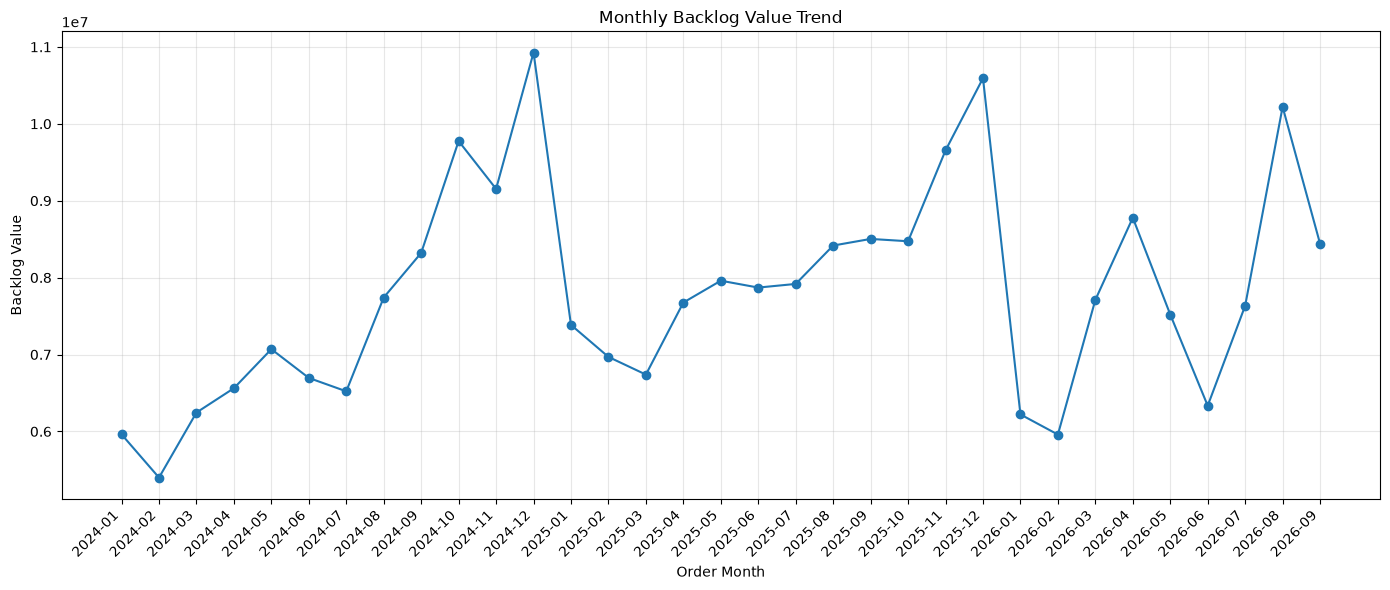

In [10]:
# Import matplotlib
import matplotlib.pyplot as plt

# Monthly Backlog Value Trend

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_backlog["order_year_month"],
    monthly_backlog["backlog_value"],
    marker="o"
)

plt.title("Monthly Backlog Value Trend")
plt.xlabel("Order Month")
plt.ylabel("Backlog Value")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Step 8 — Backlog by Order Priority

Analyze backlog performance across order priority levels.

The analysis measures:

- Total Orders
- Backlogged Orders
- Backlog Order Rate
- Backlog Quantity
- Backlog Value
- Backlog Value Rate
- Share of Total Backlog Value

This helps determine whether high-priority and urgent customer orders are disproportionately affected by backlog.

In [11]:
# Backlog analysis by order priority

priority_backlog = (
    sales_orders
    .groupby("priority")
    .agg(
        total_orders=("order_id", "nunique"),
        backlogged_orders=(
            "has_backlog_flag",
            lambda x: (x == "Y").sum()
        ),
        ordered_qty=("ordered_qty", "sum"),
        backlog_qty=("backlog_qty", "sum"),
        order_value=("order_value", "sum"),
        backlog_value=("backlog_value", "sum")
    )
    .reset_index()
)


# Calculate backlog metrics

priority_backlog["backlog_order_rate_pct"] = (
    priority_backlog["backlogged_orders"]
    / priority_backlog["total_orders"]
    * 100
)

priority_backlog["backlog_qty_rate_pct"] = (
    priority_backlog["backlog_qty"]
    / priority_backlog["ordered_qty"]
    * 100
)

priority_backlog["backlog_value_rate_pct"] = (
    priority_backlog["backlog_value"]
    / priority_backlog["order_value"]
    * 100
)

priority_backlog["backlog_value_share_pct"] = (
    priority_backlog["backlog_value"]
    / total_backlog_value
    * 100
)


priority_backlog = priority_backlog.sort_values(
    "backlog_value",
    ascending=False
)


print("BACKLOG BY ORDER PRIORITY\n")

print(
    priority_backlog[
        [
            "priority",
            "total_orders",
            "backlogged_orders",
            "backlog_order_rate_pct",
            "backlog_qty",
            "backlog_value",
            "backlog_value_rate_pct",
            "backlog_value_share_pct"
        ]
    ].to_string(
        index=False,
        formatters={
            "backlog_order_rate_pct":
                lambda x: f"{x:.2f}%",
            "backlog_value":
                lambda x: f"{x:,.2f}",
            "backlog_value_rate_pct":
                lambda x: f"{x:.2f}%",
            "backlog_value_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)

BACKLOG BY ORDER PRIORITY

priority  total_orders  backlogged_orders backlog_order_rate_pct  backlog_qty  backlog_value backlog_value_rate_pct backlog_value_share_pct
  Normal         14557               6385                 43.86%        35656 149,119,216.54                 12.31%                  57.94%
    High          6359               2735                 43.01%        15213  65,058,906.65                 12.26%                  25.28%
  Urgent          2049                876                 42.75%         5222  22,287,554.70                 13.63%                   8.66%
     Low          2035                854                 41.97%         5088  20,884,241.80                 12.86%                   8.12%


## Step 9 — Backlog by Sales Channel

Analyze backlog performance across sales channels.

The analysis compares:

- Total Orders
- Backlogged Orders
- Backlog Order Rate
- Backlog Quantity
- Backlog Value
- Backlog Value Rate
- Share of Total Backlog Value

This helps identify channels with the greatest backlog exposure.

In [12]:
# Backlog analysis by sales channel

channel_backlog = (
    sales_orders
    .groupby("sales_channel")
    .agg(
        total_orders=("order_id", "nunique"),

        backlogged_orders=(
            "has_backlog_flag",
            lambda x: (x == "Y").sum()
        ),

        ordered_qty=("ordered_qty", "sum"),
        backlog_qty=("backlog_qty", "sum"),

        order_value=("order_value", "sum"),
        backlog_value=("backlog_value", "sum")
    )
    .reset_index()
)


channel_backlog["backlog_order_rate_pct"] = (
    channel_backlog["backlogged_orders"]
    / channel_backlog["total_orders"]
    * 100
)

channel_backlog["backlog_qty_rate_pct"] = (
    channel_backlog["backlog_qty"]
    / channel_backlog["ordered_qty"]
    * 100
)

channel_backlog["backlog_value_rate_pct"] = (
    channel_backlog["backlog_value"]
    / channel_backlog["order_value"]
    * 100
)

channel_backlog["backlog_value_share_pct"] = (
    channel_backlog["backlog_value"]
    / total_backlog_value
    * 100
)


channel_backlog = channel_backlog.sort_values(
    "backlog_value",
    ascending=False
)


print("BACKLOG BY SALES CHANNEL\n")

print(
    channel_backlog[
        [
            "sales_channel",
            "total_orders",
            "backlogged_orders",
            "backlog_order_rate_pct",
            "backlog_qty",
            "backlog_value",
            "backlog_value_rate_pct",
            "backlog_value_share_pct"
        ]
    ].to_string(
        index=False,
        formatters={
            "backlog_order_rate_pct":
                lambda x: f"{x:.2f}%",
            "backlog_value":
                lambda x: f"{x:,.2f}",
            "backlog_value_rate_pct":
                lambda x: f"{x:.2f}%",
            "backlog_value_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)

BACKLOG BY SALES CHANNEL

sales_channel  total_orders  backlogged_orders backlog_order_rate_pct  backlog_qty backlog_value backlog_value_rate_pct backlog_value_share_pct
       Online          7851               3406                 43.38%        19626 82,144,721.32                 12.73%                  31.92%
       Direct          7195               3136                 43.59%        17958 77,395,000.01                 12.67%                  30.07%
  Distributor          5469               2362                 43.19%        12614 53,122,927.59                 11.74%                  20.64%
  Marketplace          4485               1946                 43.39%        10981 44,687,270.77                 12.42%                  17.36%



## Step 10 — Backlog by Customer Segment

Analyze backlog performance across customer segments.

Customer information is merged with Sales Orders to measure:

- Total Orders
- Backlogged Orders
- Backlog Order Rate
- Backlog Quantity
- Backlog Value
- Backlog Value Rate
- Share of Total Backlog Value

This helps identify customer groups with the greatest exposure to unfulfilled demand.

In [13]:
# Merge customer segment into Sales Orders

backlog_customer = sales_orders.merge(
    customers[
        [
            "customer_id",
            "customer_segment"
        ]
    ],
    on="customer_id",
    how="left"
)


print(
    "Missing Customer Segment After Merge :",
    backlog_customer["customer_segment"].isna().sum()
)


# Backlog by customer segment

segment_backlog = (
    backlog_customer
    .groupby("customer_segment")
    .agg(
        total_orders=("order_id", "nunique"),

        backlogged_orders=(
            "has_backlog_flag",
            lambda x: (x == "Y").sum()
        ),

        ordered_qty=("ordered_qty", "sum"),
        backlog_qty=("backlog_qty", "sum"),

        order_value=("order_value", "sum"),
        backlog_value=("backlog_value", "sum")
    )
    .reset_index()
)


segment_backlog["backlog_order_rate_pct"] = (
    segment_backlog["backlogged_orders"]
    / segment_backlog["total_orders"]
    * 100
)

segment_backlog["backlog_qty_rate_pct"] = (
    segment_backlog["backlog_qty"]
    / segment_backlog["ordered_qty"]
    * 100
)

segment_backlog["backlog_value_rate_pct"] = (
    segment_backlog["backlog_value"]
    / segment_backlog["order_value"]
    * 100
)

segment_backlog["backlog_value_share_pct"] = (
    segment_backlog["backlog_value"]
    / total_backlog_value
    * 100
)


segment_backlog = segment_backlog.sort_values(
    "backlog_value",
    ascending=False
)


print("\nBACKLOG BY CUSTOMER SEGMENT\n")

print(
    segment_backlog[
        [
            "customer_segment",
            "total_orders",
            "backlogged_orders",
            "backlog_order_rate_pct",
            "backlog_qty",
            "backlog_value",
            "backlog_value_rate_pct",
            "backlog_value_share_pct"
        ]
    ].to_string(
        index=False,
        formatters={
            "backlog_order_rate_pct":
                lambda x: f"{x:.2f}%",
            "backlog_value":
                lambda x: f"{x:,.2f}",
            "backlog_value_rate_pct":
                lambda x: f"{x:.2f}%",
            "backlog_value_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)

Missing Customer Segment After Merge : 0

BACKLOG BY CUSTOMER SEGMENT

customer_segment  total_orders  backlogged_orders backlog_order_rate_pct  backlog_qty backlog_value backlog_value_rate_pct backlog_value_share_pct
          Retail          9269               4049                 43.68%        22662 94,650,509.07                 12.30%                  36.78%
             SMB          7856               3405                 43.34%        19341 83,281,559.27                 12.84%                  32.36%
      Enterprise          4298               1868                 43.46%        10721 43,362,926.22                 12.33%                  16.85%
     Distributor          3577               1528                 42.72%         8455 36,054,925.13                 12.09%                  14.01%


## Step 11 — Backlog by Customer Region

Analyze backlog performance across customer regions.

The analysis measures:

- Total Orders
- Backlogged Orders
- Backlog Order Rate
- Backlog Quantity
- Backlog Value
- Backlog Value Rate
- Share of Total Backlog Value

This helps identify geographic areas with the greatest exposure to unfulfilled customer demand.

In [14]:
# Merge customer region into Sales Orders

backlog_region = sales_orders.merge(
    customers[
        [
            "customer_id",
            "region"
        ]
    ],
    on="customer_id",
    how="left"
)


print(
    "Missing Customer Region After Merge :",
    backlog_region["region"].isna().sum()
)


# Backlog by customer region

regional_backlog = (
    backlog_region
    .groupby("region")
    .agg(
        total_orders=("order_id", "nunique"),

        backlogged_orders=(
            "has_backlog_flag",
            lambda x: (x == "Y").sum()
        ),

        ordered_qty=("ordered_qty", "sum"),
        backlog_qty=("backlog_qty", "sum"),

        order_value=("order_value", "sum"),
        backlog_value=("backlog_value", "sum")
    )
    .reset_index()
)


regional_backlog["backlog_order_rate_pct"] = (
    regional_backlog["backlogged_orders"]
    / regional_backlog["total_orders"]
    * 100
)

regional_backlog["backlog_qty_rate_pct"] = (
    regional_backlog["backlog_qty"]
    / regional_backlog["ordered_qty"]
    * 100
)

regional_backlog["backlog_value_rate_pct"] = (
    regional_backlog["backlog_value"]
    / regional_backlog["order_value"]
    * 100
)

regional_backlog["backlog_value_share_pct"] = (
    regional_backlog["backlog_value"]
    / total_backlog_value
    * 100
)


regional_backlog = regional_backlog.sort_values(
    "backlog_value",
    ascending=False
)


print("\nBACKLOG BY CUSTOMER REGION\n")

print(
    regional_backlog[
        [
            "region",
            "total_orders",
            "backlogged_orders",
            "backlog_order_rate_pct",
            "backlog_qty",
            "backlog_value",
            "backlog_value_rate_pct",
            "backlog_value_share_pct"
        ]
    ].to_string(
        index=False,
        formatters={
            "backlog_order_rate_pct":
                lambda x: f"{x:.2f}%",
            "backlog_value":
                lambda x: f"{x:,.2f}",
            "backlog_value_rate_pct":
                lambda x: f"{x:.2f}%",
            "backlog_value_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)

Missing Customer Region After Merge : 0

BACKLOG BY CUSTOMER REGION

 region  total_orders  backlogged_orders backlog_order_rate_pct  backlog_qty backlog_value backlog_value_rate_pct backlog_value_share_pct
  South          6995               3061                 43.76%        16851 69,516,265.10                 11.94%                  27.01%
   West          6198               2647                 42.71%        14319 62,964,636.70                 12.25%                  24.47%
  North          4741               2114                 44.59%        12671 52,984,977.46                 13.42%                  20.59%
   East          3906               1637                 41.91%         9395 39,179,079.22                 12.13%                  15.22%
Central          3160               1391                 44.02%         7943 32,704,961.21                 12.85%                  12.71%


## Step 12 — Backlog by Product Category

Analyze backlog exposure across product categories using Sales Order Items.

The analysis measures:

- Total Order Lines
- Backlogged Lines
- Backlog Line Rate
- Ordered Quantity
- Backlog Quantity
- Net Order Value
- Backlog Value
- Backlog Value Rate
- Share of Total Backlog Value

This helps identify product categories responsible for the greatest amount of unfulfilled demand.

In [15]:
# Merge product category into Sales Order Items

backlog_product = sales_order_items.merge(
    products[
        [
            "product_id",
            "category",
            "product_name"
        ]
    ],
    on="product_id",
    how="left"
)


print(
    "Missing Product Category After Merge :",
    backlog_product["category"].isna().sum()
)


# Backlog by product category

category_backlog = (
    backlog_product
    .groupby("category")
    .agg(
        total_lines=("order_item_id", "count"),

        backlogged_lines=(
            "backlog_qty",
            lambda x: (x > 0).sum()
        ),

        ordered_qty=("ordered_qty", "sum"),
        backlog_qty=("backlog_qty", "sum"),

        net_order_value=("net_order_value", "sum"),
        backlog_value=("backlog_value", "sum")
    )
    .reset_index()
)


category_backlog["backlog_line_rate_pct"] = (
    category_backlog["backlogged_lines"]
    / category_backlog["total_lines"]
    * 100
)

category_backlog["backlog_qty_rate_pct"] = (
    category_backlog["backlog_qty"]
    / category_backlog["ordered_qty"]
    * 100
)

category_backlog["backlog_value_rate_pct"] = (
    category_backlog["backlog_value"]
    / category_backlog["net_order_value"]
    * 100
)

category_backlog["backlog_value_share_pct"] = (
    category_backlog["backlog_value"]
    / total_backlog_value
    * 100
)


category_backlog = category_backlog.sort_values(
    "backlog_value",
    ascending=False
)


print("\nBACKLOG BY PRODUCT CATEGORY\n")

print(
    category_backlog[
        [
            "category",
            "total_lines",
            "backlogged_lines",
            "backlog_line_rate_pct",
            "backlog_qty",
            "backlog_value",
            "backlog_value_rate_pct",
            "backlog_value_share_pct"
        ]
    ].to_string(
        index=False,
        formatters={
            "backlog_line_rate_pct":
                lambda x: f"{x:.2f}%",
            "backlog_value":
                lambda x: f"{x:,.2f}",
            "backlog_value_rate_pct":
                lambda x: f"{x:.2f}%",
            "backlog_value_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)

Missing Product Category After Merge : 0

BACKLOG BY PRODUCT CATEGORY

              category  total_lines  backlogged_lines backlog_line_rate_pct  backlog_qty backlog_value backlog_value_rate_pct backlog_value_share_pct
           Electronics        16347              3620                22.14%        16224 72,419,213.94                 12.18%                  28.14%
       Office Supplies        11401              2376                20.84%        11107 49,295,528.24                 12.55%                  19.16%
Health & Personal Care        11161              2438                21.84%        11312 46,802,484.94                 12.72%                  18.19%
            Automotive        10904              2509                23.01%        11831 45,572,410.77                 13.64%                  17.71%
        Home & Kitchen        11584              2335                20.16%        10705 43,260,281.80                 11.40%                  16.81%


## Step 13 — Top Products by Backlog Value

Identify individual products with the highest backlog exposure.

The analysis measures:

- Backlogged Order Lines
- Backlog Quantity
- Backlog Value
- Share of Total Backlog Value

This helps identify specific SKUs that should receive greater attention when addressing unfulfilled customer demand.

In [16]:
# Product-level backlog analysis

product_backlog = (
    backlog_product[
        backlog_product["backlog_qty"] > 0
    ]
    .groupby(
        [
            "product_id",
            "product_name",
            "category"
        ]
    )
    .agg(
        backlogged_lines=("order_item_id", "count"),
        backlog_qty=("backlog_qty", "sum"),
        backlog_value=("backlog_value", "sum")
    )
    .reset_index()
)


product_backlog["backlog_value_share_pct"] = (
    product_backlog["backlog_value"]
    / total_backlog_value
    * 100
)


product_backlog = product_backlog.sort_values(
    "backlog_value",
    ascending=False
)


top_10_backlog_products = (
    product_backlog.head(10).copy()
)


print("TOP 10 PRODUCTS BY BACKLOG VALUE\n")

print(
    top_10_backlog_products.to_string(
        index=False,
        formatters={
            "backlog_value":
                lambda x: f"{x:,.2f}",
            "backlog_value_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)


print(
    "\nTop 10 Product Backlog Value :",
    f"{top_10_backlog_products['backlog_value'].sum():,.2f}"
)

print(
    "Top 10 Share of Total Backlog :",
    f"{top_10_backlog_products['backlog_value'].sum() / total_backlog_value * 100:.2f}%"
)

TOP 10 PRODUCTS BY BACKLOG VALUE

product_id               product_name               category  backlogged_lines  backlog_qty backlog_value backlog_value_share_pct
   SKU0228 Smart Devices Product 0228            Electronics               247         1099  9,876,135.18                   3.84%
   SKU0029   Maintenance Product 0029             Automotive               219          927  6,238,062.68                   2.42%
   SKU0157      Grooming Product 0157 Health & Personal Care               167          750  5,734,736.23                   2.23%
   SKU0006   Accessories Product 0006             Automotive               105          653  4,627,727.74                   1.80%
   SKU0217     Furniture Product 0217        Office Supplies               194         1118  4,263,155.72                   1.66%
   SKU0074   Maintenance Product 0074             Automotive               134          623  4,042,512.31                   1.57%
   SKU0201      Cookware Product 0201         Home & Kit

## Step 14 — Backlog by Warehouse

Analyze backlog exposure across fulfillment warehouses.

The analysis measures:

- Total Orders
- Backlogged Orders
- Backlog Order Rate
- Backlog Quantity
- Backlog Value
- Backlog Value Rate
- Share of Total Backlog Value

This helps identify warehouses associated with the greatest level of unfulfilled customer demand.

In [17]:
# Merge warehouse information into Sales Orders

warehouse_backlog_data = sales_orders.merge(
    warehouses[
        [
            "warehouse_id",
            "warehouse_name",
            "region"
        ]
    ],
    on="warehouse_id",
    how="left",
    suffixes=("", "_warehouse")
)


print(
    "Missing Warehouse Name After Merge :",
    warehouse_backlog_data["warehouse_name"].isna().sum()
)


# Backlog analysis by warehouse

warehouse_backlog = (
    warehouse_backlog_data
    .groupby(
        [
            "warehouse_id",
            "warehouse_name"
        ]
    )
    .agg(
        total_orders=("order_id", "nunique"),

        backlogged_orders=(
            "has_backlog_flag",
            lambda x: (x == "Y").sum()
        ),

        ordered_qty=("ordered_qty", "sum"),
        backlog_qty=("backlog_qty", "sum"),

        order_value=("order_value", "sum"),
        backlog_value=("backlog_value", "sum")
    )
    .reset_index()
)


warehouse_backlog["backlog_order_rate_pct"] = (
    warehouse_backlog["backlogged_orders"]
    / warehouse_backlog["total_orders"]
    * 100
)

warehouse_backlog["backlog_qty_rate_pct"] = (
    warehouse_backlog["backlog_qty"]
    / warehouse_backlog["ordered_qty"]
    * 100
)

warehouse_backlog["backlog_value_rate_pct"] = (
    warehouse_backlog["backlog_value"]
    / warehouse_backlog["order_value"]
    * 100
)

warehouse_backlog["backlog_value_share_pct"] = (
    warehouse_backlog["backlog_value"]
    / total_backlog_value
    * 100
)


warehouse_backlog = warehouse_backlog.sort_values(
    "backlog_value",
    ascending=False
)


print("\nBACKLOG BY WAREHOUSE\n")

print(
    warehouse_backlog[
        [
            "warehouse_id",
            "warehouse_name",
            "total_orders",
            "backlogged_orders",
            "backlog_order_rate_pct",
            "backlog_qty",
            "backlog_value",
            "backlog_value_rate_pct",
            "backlog_value_share_pct"
        ]
    ].to_string(
        index=False,
        formatters={
            "backlog_order_rate_pct":
                lambda x: f"{x:.2f}%",
            "backlog_value":
                lambda x: f"{x:,.2f}",
            "backlog_value_rate_pct":
                lambda x: f"{x:.2f}%",
            "backlog_value_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)

Missing Warehouse Name After Merge : 0

BACKLOG BY WAREHOUSE

warehouse_id    warehouse_name  total_orders  backlogged_orders backlog_order_rate_pct  backlog_qty backlog_value backlog_value_rate_pct backlog_value_share_pct
        WH01 Bengaluru Central          5457               2372                 43.47%        13206 54,695,898.76                 12.27%                  21.25%
        WH03         Delhi NCR          4812               2058                 42.77%        11406 48,819,037.44                 12.00%                  18.97%
        WH02       Mumbai West          4441               1923                 43.30%        10506 45,202,756.42                 12.27%                  17.56%
        WH05       Chennai Hub          3458               1520                 43.96%         9018 37,705,603.63                 13.20%                  14.65%
        WH04   Hyderabad South          3566               1535                 43.05%         8564 36,133,244.76                 12.

## Step 15 — High-Value Backlog Exposure

Identify individual orders with the highest backlog value.

The analysis highlights high-value customer orders that represent the greatest financial exposure within the backlog.

For each order, the analysis displays:

- Order ID
- Customer ID
- Order Date
- Priority
- Sales Channel
- Ordered Quantity
- Backlog Quantity
- Backlog Percentage
- Order Value
- Backlog Value

In [18]:
# Top high-value backlogged orders

top_backlog_orders = (
    backlogged_orders[
        [
            "order_id",
            "customer_id",
            "order_date",
            "priority",
            "sales_channel",
            "ordered_qty",
            "backlog_qty",
            "backlog_pct",
            "order_value",
            "backlog_value"
        ]
    ]
    .sort_values(
        "backlog_value",
        ascending=False
    )
    .head(10)
)


print("TOP 10 HIGH-VALUE BACKLOG ORDERS\n")

print(
    top_backlog_orders.to_string(
        index=False,
        formatters={
            "backlog_pct":
                lambda x: f"{x:.2f}%",
            "order_value":
                lambda x: f"{x:,.2f}",
            "backlog_value":
                lambda x: f"{x:,.2f}"
        }
    )
)


top_10_order_backlog = (
    top_backlog_orders["backlog_value"].sum()
)


print(
    "\nTop 10 Orders Backlog Value :",
    f"{top_10_order_backlog:,.2f}"
)

print(
    "Top 10 Orders Share of Total Backlog :",
    f"{top_10_order_backlog / total_backlog_value * 100:.2f}%"
)

TOP 10 HIGH-VALUE BACKLOG ORDERS

order_id customer_id order_date priority sales_channel  ordered_qty  backlog_qty backlog_pct order_value backlog_value
SO003156   CUST00892 2026-05-07   Normal        Direct          117           99      84.62%  841,264.36    719,326.18
SO009223   CUST01543 2026-08-05   Normal   Marketplace          103           92      89.32%  782,448.67    716,629.81
SO004557   CUST01161 2026-09-18     High        Online           80           80     100.00%  688,988.00    688,988.00
SO013986   CUST00152 2026-08-11     High   Distributor           80           77      96.25%  669,309.88    645,981.49
SO019850   CUST01907 2024-10-23      Low   Distributor          104           70      67.31%  626,670.71    577,724.00
SO007324   CUST02009 2025-07-10     High        Online           80           72      90.00%  573,096.53    531,007.20
SO020248   CUST01306 2025-01-30   Normal        Direct           84           66      78.57%  607,213.03    473,888.76
SO002581   CUS

## Step 16 — Backlog Concentration by Customer

Analyze customer-level backlog concentration to determine whether overall backlog exposure depends heavily on a small number of customers.

The analysis identifies the Top 10 customers by backlog value and calculates their combined share of total backlog.

In [19]:
# Customer-level backlog concentration

customer_backlog = (
    backlog_customer[
        backlog_customer["backlog_qty"] > 0
    ]
    .groupby("customer_id")
    .agg(
        backlogged_orders=("order_id", "nunique"),
        backlog_qty=("backlog_qty", "sum"),
        backlog_value=("backlog_value", "sum")
    )
    .reset_index()
    .sort_values(
        "backlog_value",
        ascending=False
    )
)


top_10_backlog_customers = (
    customer_backlog.head(10).copy()
)


top_10_customer_backlog_value = (
    top_10_backlog_customers[
        "backlog_value"
    ].sum()
)


top_10_customer_backlog_share = (
    top_10_customer_backlog_value
    / total_backlog_value
    * 100
)


print("TOP 10 CUSTOMERS BY BACKLOG VALUE\n")

print(
    top_10_backlog_customers.to_string(
        index=False,
        formatters={
            "backlog_value":
                lambda x: f"{x:,.2f}"
        }
    )
)


print(
    "\nTop 10 Customer Backlog Value :",
    f"{top_10_customer_backlog_value:,.2f}"
)

print(
    "Top 10 Customer Share of Total Backlog :",
    f"{top_10_customer_backlog_share:.2f}%"
)

TOP 10 CUSTOMERS BY BACKLOG VALUE

customer_id  backlogged_orders  backlog_qty backlog_value
  CUST01543                  9          139    893,641.48
  CUST01672                  8          118    838,731.28
  CUST00892                  6          120    786,646.76
  CUST01161                  5           95    768,031.41
  CUST02009                  6          126    750,250.44
  CUST00152                  3           87    700,038.30
  CUST01306                  7          105    692,191.93
  CUST01000                  6          119    665,624.89
  CUST01907                  5           80    639,391.05
  CUST01933                  4          110    600,371.97

Top 10 Customer Backlog Value : 7,334,919.51
Top 10 Customer Share of Total Backlog : 2.85%


## Step 17 — Backlog by Year

Analyze backlog performance by order year.

The analysis compares:

- Total Orders
- Backlogged Orders
- Backlog Order Rate
- Ordered Quantity
- Backlog Quantity
- Backlog Quantity Rate
- Total Order Value
- Backlog Value
- Backlog Value Rate

Note: 2026 contains data only through September, so annual totals should not be directly compared with the complete 2024 and 2025 years.

In [20]:
# Backlog analysis by year

yearly_backlog = (
    sales_orders
    .groupby("order_year")
    .agg(
        total_orders=("order_id", "nunique"),

        backlogged_orders=(
            "has_backlog_flag",
            lambda x: (x == "Y").sum()
        ),

        ordered_qty=("ordered_qty", "sum"),
        backlog_qty=("backlog_qty", "sum"),

        order_value=("order_value", "sum"),
        backlog_value=("backlog_value", "sum")
    )
    .reset_index()
)


yearly_backlog["backlog_order_rate_pct"] = (
    yearly_backlog["backlogged_orders"]
    / yearly_backlog["total_orders"]
    * 100
)

yearly_backlog["backlog_qty_rate_pct"] = (
    yearly_backlog["backlog_qty"]
    / yearly_backlog["ordered_qty"]
    * 100
)

yearly_backlog["backlog_value_rate_pct"] = (
    yearly_backlog["backlog_value"]
    / yearly_backlog["order_value"]
    * 100
)


print("BACKLOG BY YEAR\n")

print(
    yearly_backlog[
        [
            "order_year",
            "total_orders",
            "backlogged_orders",
            "backlog_order_rate_pct",
            "backlog_qty",
            "backlog_qty_rate_pct",
            "backlog_value",
            "backlog_value_rate_pct"
        ]
    ].to_string(
        index=False,
        formatters={
            "backlog_order_rate_pct":
                lambda x: f"{x:.2f}%",
            "backlog_qty_rate_pct":
                lambda x: f"{x:.2f}%",
            "backlog_value":
                lambda x: f"{x:,.2f}",
            "backlog_value_rate_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)

BACKLOG BY YEAR

 order_year  total_orders  backlogged_orders backlog_order_rate_pct  backlog_qty backlog_qty_rate_pct backlog_value backlog_value_rate_pct
       2024          9273               3944                 42.53%        21636               11.72% 90,374,106.50                 11.92%
       2025          9356               4112                 43.95%        23444               12.38% 98,156,485.95                 12.56%
       2026          6371               2794                 43.85%        16099               12.61% 68,819,327.24                 13.02%


## Step 18 — Comparable January–September Backlog Analysis

Compare backlog performance across 2024, 2025, and 2026 using only January through September.

Using the same nine-month period removes the distortion caused by incomplete 2026 data and provides a more reliable year-over-year comparison.

The analysis focuses on:

- Backlog Order Rate
- Backlog Quantity Rate
- Backlog Value
- Backlog Value Rate
- Year-over-Year Backlog Value Growth

In [21]:
# Filter comparable January-September period

jan_sep_backlog = sales_orders[
    sales_orders["order_month_no"] <= 9
].copy()


# Aggregate comparable yearly backlog

comparable_backlog = (
    jan_sep_backlog
    .groupby("order_year")
    .agg(
        total_orders=("order_id", "nunique"),

        backlogged_orders=(
            "has_backlog_flag",
            lambda x: (x == "Y").sum()
        ),

        ordered_qty=("ordered_qty", "sum"),
        backlog_qty=("backlog_qty", "sum"),

        order_value=("order_value", "sum"),
        backlog_value=("backlog_value", "sum")
    )
    .reset_index()
)


# Calculate backlog rates

comparable_backlog["backlog_order_rate_pct"] = (
    comparable_backlog["backlogged_orders"]
    / comparable_backlog["total_orders"]
    * 100
)

comparable_backlog["backlog_qty_rate_pct"] = (
    comparable_backlog["backlog_qty"]
    / comparable_backlog["ordered_qty"]
    * 100
)

comparable_backlog["backlog_value_rate_pct"] = (
    comparable_backlog["backlog_value"]
    / comparable_backlog["order_value"]
    * 100
)


# YoY growth in backlog value

comparable_backlog["backlog_value_yoy_pct"] = (
    comparable_backlog["backlog_value"]
    .pct_change()
    * 100
)


print("COMPARABLE JAN-SEP BACKLOG ANALYSIS\n")

print(
    comparable_backlog[
        [
            "order_year",
            "total_orders",
            "backlogged_orders",
            "backlog_order_rate_pct",
            "backlog_qty",
            "backlog_qty_rate_pct",
            "backlog_value",
            "backlog_value_rate_pct",
            "backlog_value_yoy_pct"
        ]
    ].to_string(
        index=False,
        formatters={
            "backlog_order_rate_pct":
                lambda x: f"{x:.2f}%",

            "backlog_qty_rate_pct":
                lambda x: f"{x:.2f}%",

            "backlog_value":
                lambda x: f"{x:,.2f}",

            "backlog_value_rate_pct":
                lambda x: f"{x:.2f}%",

            "backlog_value_yoy_pct":
                lambda x: (
                    "-"
                    if pd.isna(x)
                    else f"{x:.2f}%"
                )
        }
    )
)

COMPARABLE JAN-SEP BACKLOG ANALYSIS

 order_year  total_orders  backlogged_orders backlog_order_rate_pct  backlog_qty backlog_qty_rate_pct backlog_value backlog_value_rate_pct backlog_value_yoy_pct
       2024          6314               2656                 42.07%        14466               11.49% 60,518,852.49                 11.71%                   NaN
       2025          6286               2779                 44.21%        16203               12.65% 69,437,101.21                 13.11%                14.74%
       2026          6371               2794                 43.85%        16099               12.61% 68,819,327.24                 13.02%                -0.89%


## Step 19 — Quarterly Backlog Analysis

Analyze backlog performance by year and quarter.

The analysis measures:

- Total Orders
- Backlogged Orders
- Backlog Order Rate
- Backlog Quantity
- Backlog Quantity Rate
- Backlog Value
- Backlog Value Rate

This helps identify quarterly changes in backlog pressure and potential seasonal patterns.

In [22]:
# Quarterly backlog analysis

quarterly_backlog = (
    sales_orders
    .groupby(
        [
            "order_year",
            "order_quarter"
        ]
    )
    .agg(
        total_orders=("order_id", "nunique"),

        backlogged_orders=(
            "has_backlog_flag",
            lambda x: (x == "Y").sum()
        ),

        ordered_qty=("ordered_qty", "sum"),
        backlog_qty=("backlog_qty", "sum"),

        order_value=("order_value", "sum"),
        backlog_value=("backlog_value", "sum")
    )
    .reset_index()
)


quarterly_backlog["backlog_order_rate_pct"] = (
    quarterly_backlog["backlogged_orders"]
    / quarterly_backlog["total_orders"]
    * 100
)

quarterly_backlog["backlog_qty_rate_pct"] = (
    quarterly_backlog["backlog_qty"]
    / quarterly_backlog["ordered_qty"]
    * 100
)

quarterly_backlog["backlog_value_rate_pct"] = (
    quarterly_backlog["backlog_value"]
    / quarterly_backlog["order_value"]
    * 100
)


print("QUARTERLY BACKLOG ANALYSIS\n")

print(
    quarterly_backlog[
        [
            "order_year",
            "order_quarter",
            "total_orders",
            "backlogged_orders",
            "backlog_order_rate_pct",
            "backlog_qty",
            "backlog_qty_rate_pct",
            "backlog_value",
            "backlog_value_rate_pct"
        ]
    ].to_string(
        index=False,
        formatters={
            "backlog_order_rate_pct":
                lambda x: f"{x:.2f}%",

            "backlog_qty_rate_pct":
                lambda x: f"{x:.2f}%",

            "backlog_value":
                lambda x: f"{x:,.2f}",

            "backlog_value_rate_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)

QUARTERLY BACKLOG ANALYSIS

 order_year order_quarter  total_orders  backlogged_orders backlog_order_rate_pct  backlog_qty backlog_qty_rate_pct backlog_value backlog_value_rate_pct
       2024            Q1          1952                788                 40.37%         4210               10.89% 17,607,506.58                 11.33%
       2024            Q2          2121                896                 42.24%         4747               11.32% 20,327,247.39                 11.54%
       2024            Q3          2241                972                 43.37%         5509               12.16% 22,584,098.52                 12.19%
       2024            Q4          2959               1288                 43.53%         7170               12.21% 29,855,254.01                 12.35%
       2025            Q1          1915                846                 44.18%         4845               12.38% 21,093,018.26                 12.97%
       2025            Q2          2128               

## Step 20 — Backlog Value by Severity

Visualize backlog value across severity levels.

This highlights how much financial exposure is associated with Low, Moderate, High, and Critical backlog conditions.

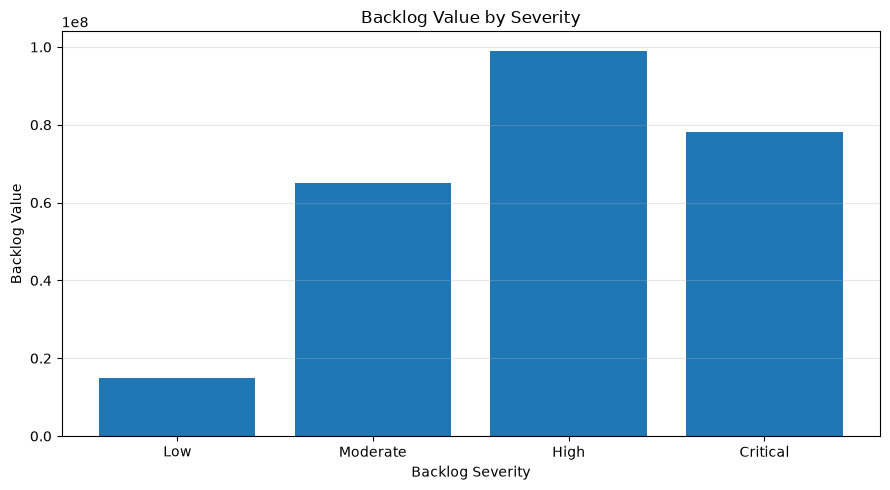

In [23]:
# Backlog Value by Severity

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    backlog_severity_summary["backlog_severity"].astype(str),
    backlog_severity_summary["backlog_value"]
)

plt.title("Backlog Value by Severity")

plt.xlabel("Backlog Severity")
plt.ylabel("Backlog Value")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

## Step 21 — Backlog Value by Product Category

Visualize total backlog value across product categories.

This provides a clear comparison of the product groups contributing the most to unfulfilled sales demand.

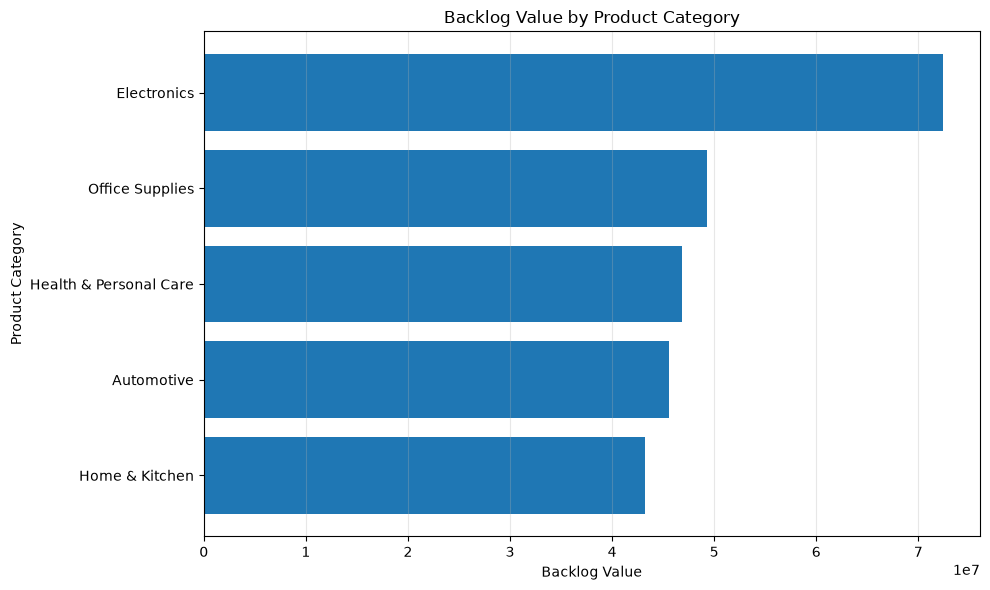

In [24]:
# Backlog Value by Product Category

plt.figure(figsize=(10, 6))

category_plot = category_backlog.sort_values(
    "backlog_value",
    ascending=True
)

plt.barh(
    category_plot["category"],
    category_plot["backlog_value"]
)

plt.title("Backlog Value by Product Category")

plt.xlabel("Backlog Value")
plt.ylabel("Product Category")

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.show()

## Step 22 — Top Backlog Risk Areas Summary

Summarize the major backlog risk areas identified across priority, channel, customer segment, region, product category, warehouse, and product-level analyses.

This provides a concise management-level view of where backlog exposure is highest.

In [25]:
# Identify major backlog risk areas

top_priority = priority_backlog.loc[
    priority_backlog["backlog_value"].idxmax()
]

highest_priority_rate = priority_backlog.loc[
    priority_backlog["backlog_value_rate_pct"].idxmax()
]

top_channel = channel_backlog.loc[
    channel_backlog["backlog_value"].idxmax()
]

top_segment = segment_backlog.loc[
    segment_backlog["backlog_value"].idxmax()
]

top_region = regional_backlog.loc[
    regional_backlog["backlog_value"].idxmax()
]

highest_region_rate = regional_backlog.loc[
    regional_backlog["backlog_value_rate_pct"].idxmax()
]

top_category = category_backlog.loc[
    category_backlog["backlog_value"].idxmax()
]

highest_category_rate = category_backlog.loc[
    category_backlog["backlog_value_rate_pct"].idxmax()
]

top_warehouse = warehouse_backlog.loc[
    warehouse_backlog["backlog_value"].idxmax()
]

highest_warehouse_rate = warehouse_backlog.loc[
    warehouse_backlog["backlog_value_rate_pct"].idxmax()
]

top_product = product_backlog.loc[
    product_backlog["backlog_value"].idxmax()
]


print("TOP BACKLOG RISK AREAS SUMMARY\n")

print(
    f"Highest Backlog Priority      : "
    f"{top_priority['priority']} "
    f"({top_priority['backlog_value']:,.2f})"
)

print(
    f"Highest Priority Backlog Rate : "
    f"{highest_priority_rate['priority']} "
    f"({highest_priority_rate['backlog_value_rate_pct']:.2f}%)"
)

print(
    f"Top Sales Channel            : "
    f"{top_channel['sales_channel']} "
    f"({top_channel['backlog_value']:,.2f})"
)

print(
    f"Top Customer Segment         : "
    f"{top_segment['customer_segment']} "
    f"({top_segment['backlog_value']:,.2f})"
)

print(
    f"Top Customer Region          : "
    f"{top_region['region']} "
    f"({top_region['backlog_value']:,.2f})"
)

print(
    f"Highest Region Backlog Rate  : "
    f"{highest_region_rate['region']} "
    f"({highest_region_rate['backlog_value_rate_pct']:.2f}%)"
)

print(
    f"Top Product Category         : "
    f"{top_category['category']} "
    f"({top_category['backlog_value']:,.2f})"
)

print(
    f"Highest Category Backlog Rate: "
    f"{highest_category_rate['category']} "
    f"({highest_category_rate['backlog_value_rate_pct']:.2f}%)"
)

print(
    f"Top Warehouse                : "
    f"{top_warehouse['warehouse_name']} "
    f"({top_warehouse['backlog_value']:,.2f})"
)

print(
    f"Highest Warehouse Rate       : "
    f"{highest_warehouse_rate['warehouse_name']} "
    f"({highest_warehouse_rate['backlog_value_rate_pct']:.2f}%)"
)

print(
    f"Top Backlogged Product       : "
    f"{top_product['product_name']} "
    f"({top_product['backlog_value']:,.2f})"
)

TOP BACKLOG RISK AREAS SUMMARY

Highest Backlog Priority      : Normal (149,119,216.54)
Highest Priority Backlog Rate : Urgent (13.63%)
Top Sales Channel            : Online (82,144,721.32)
Top Customer Segment         : Retail (94,650,509.07)
Top Customer Region          : South (69,516,265.10)
Highest Region Backlog Rate  : North (13.42%)
Top Product Category         : Electronics (72,419,213.94)
Highest Category Backlog Rate: Automotive (13.64%)
Top Warehouse                : Bengaluru Central (54,695,898.76)
Highest Warehouse Rate       : Chennai Hub (13.20%)
Top Backlogged Product       : Smart Devices Product 0228 (9,876,135.18)


## Step 23 — Backlog Reconciliation

Validate backlog totals between Sales Orders and Sales Order Items.

This ensures that backlog quantities and financial values remain consistent across order-level and line-level analysis.

In [26]:
# Backlog reconciliation

order_backlog_qty = (
    sales_orders["backlog_qty"].sum()
)

line_backlog_qty = (
    sales_order_items["backlog_qty"].sum()
)

order_backlog_value = (
    sales_orders["backlog_value"].sum()
)

line_backlog_value = (
    sales_order_items["backlog_value"].sum()
)


qty_difference = (
    order_backlog_qty
    - line_backlog_qty
)

value_difference = (
    order_backlog_value
    - line_backlog_value
)


print("BACKLOG RECONCILIATION\n")

print(
    f"Order-Level Backlog Quantity : "
    f"{order_backlog_qty:,}"
)

print(
    f"Line-Level Backlog Quantity  : "
    f"{line_backlog_qty:,}"
)

print(
    f"Quantity Difference          : "
    f"{qty_difference:,}"
)

print()

print(
    f"Order-Level Backlog Value    : "
    f"{order_backlog_value:,.2f}"
)

print(
    f"Line-Level Backlog Value     : "
    f"{line_backlog_value:,.2f}"
)

print(
    f"Value Difference             : "
    f"{value_difference:,.2f}"
)


backlog_reconciliation_passed = (
    qty_difference == 0
    and abs(value_difference) < 0.01
)


print(
    "\nBACKLOG RECONCILIATION STATUS :",
    "PASSED"
    if backlog_reconciliation_passed
    else "REVIEW REQUIRED"
)

BACKLOG RECONCILIATION

Order-Level Backlog Quantity : 61,179
Line-Level Backlog Quantity  : 61,179
Quantity Difference          : 0

Order-Level Backlog Value    : 257,349,919.69
Line-Level Backlog Value     : 257,349,919.69
Value Difference             : 0.00

BACKLOG RECONCILIATION STATUS : PASSED


## Step 24 — Key Business Insights

### Overall Backlog Exposure

The business has **25,000 total orders**, of which **10,850 orders (43.40%)** contain some level of backlog.

A total of **61,179 units** remain unfulfilled, representing **12.19% of total ordered quantity**.

Total backlog value is approximately **257.35M**, equivalent to **12.44% of total order value**.

The average backlog exposure per backlogged order is approximately **23.72K**.

### Backlog Severity

Backlog exposure is concentrated in more severe fulfillment gaps.

**High-severity backlog contributes 38.50% of total backlog value**, while **Critical backlog contributes another 30.38%**.

Together, High and Critical backlog account for approximately **68.88% of total backlog value**, making these orders the primary candidates for backlog reduction initiatives.

### Priority Risk

Normal-priority orders account for the largest absolute backlog value at approximately **149.12M**, primarily because they represent the largest order volume.

However, **Urgent orders have the highest backlog value rate at 13.63%**.

This indicates that high-priority fulfillment processes require attention because urgent demand is experiencing proportionally greater backlog exposure.

### Sales Channel Exposure

The **Online channel** has the largest backlog value at approximately **82.14M**, representing **31.92% of total backlog value**.

Backlog rates are relatively similar across channels, although the Distributor channel has the lowest backlog value rate at **11.74%**.

### Customer Exposure

The **Retail segment** contributes the largest backlog value at approximately **94.65M**, representing **36.78% of total backlog**.

The **South region** has the largest absolute backlog value at approximately **69.52M**.

However, the **North region has the highest backlog value rate at 13.42%**, indicating greater proportional fulfillment pressure.

Customer concentration risk is low. The Top 10 customers account for only **2.85% of total backlog value**, showing that backlog is broadly distributed across the customer base.

### Product Exposure

**Electronics** has the largest backlog value at approximately **72.42M**, representing **28.14% of total backlog value**.

However, **Automotive has the highest category backlog value rate at 13.64%**.

**Smart Devices Product 0228** is the individual product with the largest backlog exposure at approximately **9.88M**.

The Top 10 products account for **18.78% of total backlog value**, indicating moderate product-level concentration rather than dependence on only a few SKUs.

### Warehouse Exposure

**Bengaluru Central** has the largest absolute backlog exposure at approximately **54.70M**, representing **21.25% of total backlog value**.

However, **Chennai Hub has the highest warehouse backlog value rate at 13.20%**.

These results distinguish absolute backlog workload from proportional fulfillment performance.

### Backlog Trend

Comparable January–September backlog value increased by **14.74% from 2024 to 2025**.

In 2026, comparable January–September backlog value decreased slightly by **0.89% compared with 2025**.

Despite this small improvement in absolute backlog value, the backlog value rate remains elevated at **13.02% in 2026**, compared with **11.71% during January–September 2024**.

Additionally, **2026 Q3 recorded a backlog value rate of 13.80%**, indicating continued fulfillment pressure.

### Backlog Concentration

The Top 10 highest-value backlogged orders represent only **2.17% of total backlog value**, while the Top 10 customers represent only **2.85%**.

Therefore, backlog is not primarily caused by a small number of unusually large orders or customers. It is a broader operational issue distributed across the order portfolio.

### Key Business Takeaway

The organization has a meaningful backlog exposure of approximately **257.35M**, with the greatest financial risk concentrated in **High and Critical severity orders**.

Management attention should prioritize severe backlog cases, urgent orders, Electronics and Automotive products, the North region, and warehouses with elevated backlog rates.

Because backlog is broadly distributed across customers and orders, improvement efforts should focus on systematic fulfillment and backlog-management processes rather than only resolving a small number of large accounts.

## Step 25 — Final Backlog Analysis Validation

Perform final validation of the Backlog Analysis notebook.

The validation confirms that:

- Sales Orders and Sales Order Items retain their expected row counts.
- Order-level and line-level backlog quantities reconcile.
- Order-level and line-level backlog values reconcile.
- Customer, product, and warehouse enrichment produced no unmatched records.
- All backlogged orders were assigned a severity category.
- Backlog severity totals reconcile with overall backlog value.
- Core backlog metrics contain valid values.

In [27]:
# Final Backlog Analysis validation

validation_checks = {

    "Sales Orders Row Count":
        len(sales_orders) == 25000,

    "Sales Order Items Row Count":
        len(sales_order_items) == 61397,

    "Backlog Quantity Reconciles":
        sales_orders["backlog_qty"].sum()
        == sales_order_items["backlog_qty"].sum(),

    "Backlog Value Reconciles":
        abs(
            sales_orders["backlog_value"].sum()
            - sales_order_items["backlog_value"].sum()
        ) < 0.01,

    "Customer Segment Merge Complete":
        backlog_customer["customer_segment"].isna().sum() == 0,

    "Customer Region Merge Complete":
        backlog_region["region"].isna().sum() == 0,

    "Product Category Merge Complete":
        backlog_product["category"].isna().sum() == 0,

    "Product Name Merge Complete":
        backlog_product["product_name"].isna().sum() == 0,

    "Warehouse Merge Complete":
        warehouse_backlog_data["warehouse_name"].isna().sum() == 0,

    "Backlog Severity Classification Complete":
        backlogged_orders["backlog_severity"].isna().sum() == 0,

    "Severity Order Count Reconciles":
        backlog_severity_summary["orders"].sum()
        == backlog_orders,

    "Severity Backlog Value Reconciles":
        abs(
            backlog_severity_summary["backlog_value"].sum()
            - total_backlog_value
        ) < 0.01,

    "Overall Backlog Quantity Valid":
        total_backlog_qty == 61179,

    "Overall Backlog Value Valid":
        abs(
            total_backlog_value - 257349919.69
        ) < 0.01
}


print("FINAL BACKLOG ANALYSIS VALIDATION\n")

for check, result in validation_checks.items():

    print(
        f"{check:<42} : "
        f"{'PASS' if result else 'FAIL'}"
    )


final_backlog_status = all(
    validation_checks.values()
)


print(
    "\nFINAL BACKLOG ANALYSIS STATUS :",
    "PASSED"
    if final_backlog_status
    else "REVIEW REQUIRED"
)

FINAL BACKLOG ANALYSIS VALIDATION

Sales Orders Row Count                     : PASS
Sales Order Items Row Count                : PASS
Backlog Quantity Reconciles                : PASS
Backlog Value Reconciles                   : PASS
Customer Segment Merge Complete            : PASS
Customer Region Merge Complete             : PASS
Product Category Merge Complete            : PASS
Product Name Merge Complete                : PASS
Warehouse Merge Complete                   : PASS
Backlog Severity Classification Complete   : PASS
Severity Order Count Reconciles            : PASS
Severity Backlog Value Reconciles          : PASS
Overall Backlog Quantity Valid             : PASS
Overall Backlog Value Valid                : PASS

FINAL BACKLOG ANALYSIS STATUS : PASSED
